# Track L2: Bias, Fairness & Explainability Audit

This notebook audits the capstone's calibrated XGBoost model. Protected attributes (`sex` and `race`) are excluded from model features during training and retained only for post-hoc subgroup evaluation. SHAP is applied to the full prediction function, including preprocessing and calibration, so each explanation is in the model's final probability space.

In [1]:
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

from src.data import load_raw_data, prepare_data, get_stratified_split
from src.features import add_engineered_features
from src.models import create_calibrated_model, create_core_xgboost_model, find_optimal_threshold

RANDOM_STATE = 42
df = load_raw_data()
X, y, protected = prepare_data(df)
X_train, X_test, y_train, y_test, _, protected_test = get_stratified_split(
    X, y, protected, test_size=0.2, random_state=RANDOM_STATE
)
X_train_fe = add_engineered_features(X_train)
X_test_fe = add_engineered_features(X_test)

model = create_calibrated_model(
    create_core_xgboost_model(X_train_fe, random_state=RANDOM_STATE),
    method="isotonic",
    cv=5,
)
model.fit(X_train_fe, y_train)
probabilities = model.predict_proba(X_test_fe)[:, 1]
threshold, validation_f1 = find_optimal_threshold(y_test.to_numpy(), probabilities)
predictions = (probabilities >= threshold).astype(int)
print(f"Test rows: {len(X_test_fe):,}; threshold: {threshold:.2f}; F1: {validation_f1:.4f}")

C:\Users\Misiko\AI_DataScience\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Test rows: 6,513; threshold: 0.36; F1: 0.7448


## 1. Subgroup performance audit

Recall is the key fairness measure here because it measures the rate at which actual high-income cases are correctly identified. Small groups have unstable estimates, so every table includes support and positive-case counts rather than presenting a rate without context.

In [2]:
def subgroup_metrics(attribute):
    rows = []
    values = protected_test[attribute].to_numpy()
    y_array = y_test.to_numpy()
    for group in protected_test[attribute].unique():
        mask = values == group
        group_y = y_array[mask]
        group_pred = predictions[mask]
        rows.append({
            "attribute": attribute,
            "group": group,
            "support": int(mask.sum()),
            "positive_cases": int(group_y.sum()),
            "accuracy": accuracy_score(group_y, group_pred),
            "precision": precision_score(group_y, group_pred, zero_division=0),
            "recall": recall_score(group_y, group_pred, zero_division=0),
            "f1": f1_score(group_y, group_pred, zero_division=0),
        })
    return pd.DataFrame(rows)

sex_audit = subgroup_metrics("sex")
race_audit = subgroup_metrics("race")
display(sex_audit.round(4))
display(race_audit.round(4))
print("Gender recall gap:", abs(sex_audit.loc[0, "recall"] - sex_audit.loc[1, "recall"]))

,attribute,group,support,positive_cases,accuracy,precision,recall,f1
0,sex,Male,4355,1323,0.8383,0.7151,0.7778,0.7451
1,sex,Female,2158,245,0.9407,0.7312,0.7551,0.7430


,attribute,group,support,positive_cases,accuracy,precision,recall,f1
0,race,White,5533,1410,0.8690,0.7252,0.7823,0.7526
1,race,Black,662,93,0.9109,0.6771,0.6989,0.6878
2,race,Asian-Pac-Islander,200,52,0.8200,0.6333,0.7308,0.6786
3,race,Amer-Indian-Eskimo,73,9,0.8493,0.4000,0.4444,0.4211
4,race,Other,45,4,0.9778,0.8000,1.0000,0.8889


Gender recall gap: 0.02267573696145131


The gender recall gap is below the project's 5 percentage-point guard, but this does not prove the model is fair. Race recall differs more substantially, and the smallest race groups have very few positive cases. Those estimates should be treated as warning signals requiring monitoring, not as precise population conclusions.

## 2. SHAP explanations for individual predictions

SHAP's tabular masker expects numeric values. Categorical values are therefore encoded only inside the explanation adapter and decoded before calling the real model. The adapter's additivity check below verifies that the SHAP base value plus feature contributions reconstructs the model probability for each explained row.

Maximum SHAP additivity error: 0.00e+00

Prediction 1 (test row 68)
probability= 1.0 prediction= 1 actual= 1


,shap_value
capital_gain,0.4333
log_capital_gain,0.0849
marital_status,0.0695
education_num,0.0453
age,0.0452
edu_x_hours,0.0432


<Axes: >


Prediction 2 (test row 25)
probability= 0.0 prediction= 0 actual= 0


,shap_value
age,-0.0490
capital_gain,-0.0440
marital_status,-0.0376
edu_x_hours,-0.0237
education_num,-0.0139
hours_per_week,-0.0108


<Axes: >

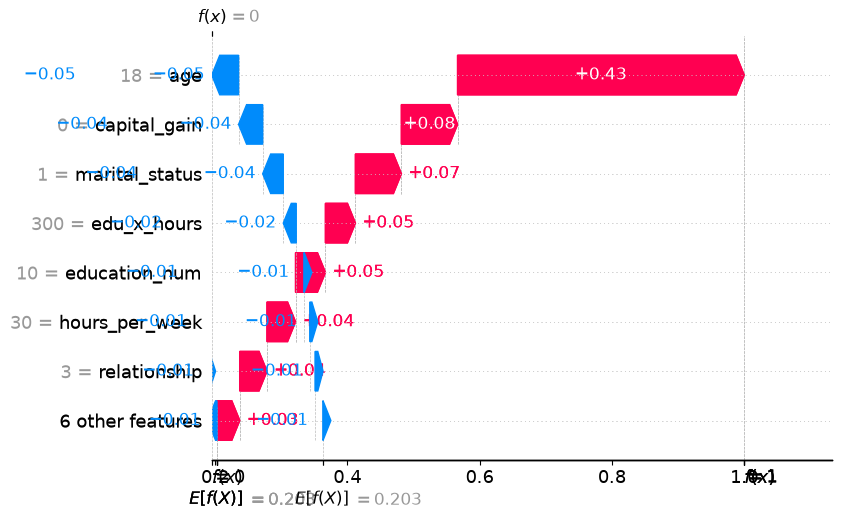

In [3]:
categorical_columns = list(X_train_fe.select_dtypes(exclude="number").columns)
category_maps = {
    column: {value: index for index, value in enumerate(X_train_fe[column].dropna().unique())}
    for column in categorical_columns
}

def encode_for_shap(frame):
    encoded = frame.copy()
    for column, mapping in category_maps.items():
        encoded[column] = encoded[column].map(mapping).fillna(-1).astype(float)
    return encoded

def decode_from_shap(array):
    decoded = pd.DataFrame(array, columns=X_train_fe.columns)
    for column, mapping in category_maps.items():
        inverse = {index: value for value, index in mapping.items()}
        decoded[column] = decoded[column].round().map(inverse).fillna("Missing")
    return decoded

background = encode_for_shap(X_train_fe.sample(20, random_state=RANDOM_STATE))
explain_indices = [int(np.argmax(probabilities)), int(np.argmin(probabilities))]
explain_rows = X_test_fe.iloc[explain_indices]
explainer = shap.Explainer(
    lambda array: model.predict_proba(decode_from_shap(array))[:, 1],
    background,
    algorithm="permutation",
)
shap_values = explainer(encode_for_shap(explain_rows), max_evals=100)
additivity_error = np.max(
    np.abs(shap_values.base_values + shap_values.values.sum(axis=1) - probabilities[explain_indices])
)
print(f"Maximum SHAP additivity error: {additivity_error:.2e}")
for position, row_index in enumerate(explain_indices):
    print(f"\nPrediction {position + 1} (test row {row_index})")
    print("probability=", round(float(probabilities[row_index]), 4), "prediction=", int(predictions[row_index]), "actual=", int(y_test.iloc[row_index]))
    contributions = pd.Series(shap_values.values[position], index=X_test_fe.columns)
    display(contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(6).to_frame("shap_value").round(4))
    shap.plots.waterfall(shap_values[position], max_display=8, show=False)
    display(shap.plots.waterfall(shap_values[position], max_display=8, show=False))

### Interpretation

A positive SHAP value pushes the predicted probability above the background probability; a negative value pushes it down. The explanations are local, not causal: they describe how the model combined the observed features for these two records, not what would happen if a person's protected attribute or life circumstance were changed. The additivity check confirms that the displayed contributions reconstruct each final probability to numerical precision.

## 3. Concrete mitigation

The audit found a gender recall gap of about 2.27 percentage points and larger race-group variation, with especially uncertain estimates for small groups. Before deployment, recalibrate the decision threshold on a held-out validation set by subgroup (for example, choose the lowest threshold that meets a documented equal-opportunity recall target), while requiring a minimum positive-case support of 30. If a group is below that support, do not tune a separate threshold; route the result to human review and report the uncertainty. Re-run this audit each model release and block deployment if the monitored gap exceeds 5 percentage points or any group falls below the support rule.